# Radar tutorial — MRMS radar next to gauges, PWS and CML for one rain event

**What this notebook does:** for one rain event it shows the NOAA MRMS radar fields
(hourly QPE, rain rate, precipitation type), puts every sensor next to the radar at its
location (gauges) or along its path (CML), prints hourly scores, and builds IDW
rainfall maps from the sensors on the radar grid.

**Data** — one knob in the setup cell, `DATASET`:

| `DATASET` | CML | ASOS | WU PWS |
|---|---|---|---|
| `'v1'` (default) | the ESSD record, [Zenodo 15287692](https://doi.org/10.5281/zenodo.15287692): `ds_openmesh.nc`, 75 CMLs, 2023-10-29 → 2024-07-01, 1 min | 1-min data of the event window, fetched from the IEM API | `pws_wu_os.nc`, [Zenodo 17508286](https://doi.org/10.5281/zenodo.17508286), used if present |
| `'v2'` | OpenMesh 2.0.0, [Zenodo 23283445](https://doi.org/10.5281/zenodo.23283445): 359 CMLs, 2023-10-29 → 2026-05-31 | 5 stations, from the record | none |

With `'v1'`, §1 downloads what is missing with the repository's own fetchers:
the ESSD archive (`src/fetch_data/OpenMesh/openmesh.py`, 13 MB zip), ASOS for a few days
around the event (`src/fetch_data/noaa_asos`), and MRMS for the event hours
(`src/fetch_data/mrms`, AWS open data); it then builds the CML attenuation file for that
window (`src/analysis/cml_baseline.py`). With `'v2'` the record is read as it is (download
`openmesh-2.0.0.zip` and run `D.install_v2(path)` once); its CML attenuation file is built
once with `python src/analysis/cml_baseline.py --dataset v2 --freq 10min`.

How to fetch other MRMS products, areas or event lists: `src/fetch_data/mrms/mrms_pipeline.ipynb`.

**Time convention:** UTC everywhere. Hourly values are mm in the hour, labelled by the
end of the hour (the MRMS QPE convention: 12:00 holds 11:00–12:00).

**Run time:** a few minutes on the first `'v1'` run (downloads), under a minute after.

In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.max_colwidth', 80)

REPO_ROOT = Path('..').resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))
from analysis import datasets as D, radar_utils as RU, rain_maps as RM, cml_baseline as CB
from fetch_data.mrms import (MRMSClient, NYC, PRECIP_FLAG, event_accumulation,
                             hourly_rainfall, domain_mean_series)

DATASET = 'v1'                   # 'v1' (the ESSD record, default) | 'v2' (Zenodo 2.0.0)
EVENT_NAME = '2024-03-23_rain'   # a row of dataset/meta/radar_events.csv
PAD_DAYS = 3                     # v1: days of ASOS / CML before the event, for the CML baseline

D.use(DATASET)
rel = lambda p: os.path.relpath(p, D.REPO_ROOT)     # paths printed relative to the repo
client = MRMSClient()
print('dataset:', DATASET, '| MRMS cache:', rel(client.cache_dir))

dataset: v1 | MRMS cache: dataset/raw/radar/mrms/cache


## §1. The event and its data

The event comes from the repository's event catalog (`dataset/meta/radar_events.csv`;
start/end = first/last wet 10-min bin over the ASOS network, UTC). The table lists the
catalog's rain events inside the v1 period (2023-10-29 → 2024-07-01) with their coverage in v1:
`asos_stations` from the catalog, `cml_sublinks` = sublinks ≥ 20 GHz on paths > 900 m
with ≥ 80 % valid 1-min signal samples in the event, `pws_stations` = WU PWS stations
with any data in the event (0 when `pws_wu_os.nc` is absent).

In [2]:
events = RU.load_event_catalog()
EVENT = events[events.event == EVENT_NAME].iloc[0]

print(f'chosen event: {EVENT.event}  ({EVENT.start} → {EVENT.end} UTC)')
if DATASET == 'v1':                                    # coverage of the v1-period rain events
    v1 = D.paths('v1')
    if not v1.cml.exists():                              # Zenodo 15287692, 13 MB zip
        from fetch_data.OpenMesh import openmesh
        openmesh.run_openmesh_pipeline(verbose=False)

    rel_ds = D.open_cml(v1.cml)
    long20 = CB.select_long_sublinks(rel_ds).query('freq_MHz >= 20000')
    pws_rel = None
    if v1.pws.exists():
        from analysis.netcdf_utils import load_pws_grouped
        pws_rel = load_pws_grouped(v1.pws, verbose=False)

    p0, p1 = (pd.Timestamp(t) for t in D.V1_PERIOD)
    rows = []
    for ev in events[(events.cls == 'rain') & (events.start >= p0) & (events.end < p1)].itertuples():
        sig = rel_ds['rsl'].sel(time=slice(ev.start, ev.end))
        valid = [float(np.isfinite(sig.isel(cml_id=r.ci, sublink_id=r.si).values).mean())
                 for r in long20.itertuples()]
        n_pws = 0 if pws_rel is None else sum(
            bool(np.isfinite(ds['rainfall_amount'].sel(time=slice(ev.start, ev.end)).values).any())
            for ds in pws_rel.values())
        rows.append(dict(event=ev.event, start=ev.start, end=ev.end, hours=ev.hours,
                         asos_mm=ev.asos_mm, asos_stations=ev.n_stations,
                         cml_sublinks=int((np.array(valid) >= 0.8).sum()), pws_stations=n_pws))
    display(pd.DataFrame(rows).set_index('event'))


chosen event: 2024-03-23_rain  (2024-03-23 00:40:00 → 2024-03-23 22:20:00 UTC)


,start,end,hours,asos_mm,asos_stations,cml_sublinks,pws_stations
event,,,,,,,
2024-03-23_rain,2024-03-23 00:40:00,2024-03-23 22:20:00,21.667,68.885,5,26,37
2024-04-01_rain,2024-04-01 12:40:00,2024-04-04 15:10:00,74.500,57.861,5,26,37
2023-12-17_rain,2023-12-17 18:00:00,2023-12-18 19:30:00,25.500,34.925,4,13,30
2023-11-21_rain,2023-11-21 14:30:00,2023-11-22 12:20:00,21.833,37.973,4,28,28


**Files of the chosen dataset.** With `'v1'` this cell fetches ASOS for the event
± `PAD_DAYS` days (5 stations: EWR, JFK, LGA, NYC, TEB) and builds the 10-min CML
attenuation file for the same window; both are skipped when the files already cover it.
The table lists each file the notebook reads and whether it is on disk.

In [3]:
p = D.paths()
if DATASET == 'v1':
    day0 = (EVENT.start - pd.Timedelta(days=PAD_DAYS)).normalize()
    day1 = EVENT.end.normalize() + pd.Timedelta(days=1)
    D.fetch_v1_asos(day0, day1)
    window = (f'{day0:%Y-%m-%d}', f'{day1 + pd.Timedelta(days=1):%Y-%m-%d}')
    if not CB.covers(p.baselines_10min, window):
        CB.main(['--dataset', 'v1', '--freq', '10min', '--window', *window])
    print(f'ASOS window: {D.asos_window(p.asos)[0]:%Y-%m-%d} → {D.asos_window(p.asos)[1]:%Y-%m-%d} (days)')
else:
    for k in ('asos', 'baselines_10min'):
        p.require(k)                                   # clear error if the file is missing

used = ['cml', 'asos', 'pws', 'mesonet', 'baselines_10min']
pd.DataFrame([dict(file=k, path=rel(getattr(p, k)) if getattr(p, k) else '—',
                   on_disk=p.available()[k]) for k in used]).set_index('file')

ASOS window: 2024-03-20 → 2024-03-24 (days)


,path,on_disk
file,,
cml,dataset/raw/openmesh/ds_openmesh.nc,True
asos,dataset/raw/openmesh/derived/asos_v1.nc,True
pws,dataset/raw/openmesh/pws_wu_os.nc,True
mesonet,—,False
baselines_10min,dataset/raw/openmesh/derived/cml_attenuation_baselines_10min.nc,True


## §2. MRMS fields for the event

Hourly QPE over the NYC crop (40.48–40.93 N, 74.27–73.68 W), fetched and cached by
`src/fetch_data/mrms`. Left: event total of the gauge-corrected `MultiSensor_QPE_01H_Pass2`;
right: event total of `RadarOnly_QPE_01H`; same color scale (mm). x = longitude,
y = latitude (°). The line above the maps gives the hours available in the archive.

Pass 2: 23/23 hours, radar-only: 23/23 hours


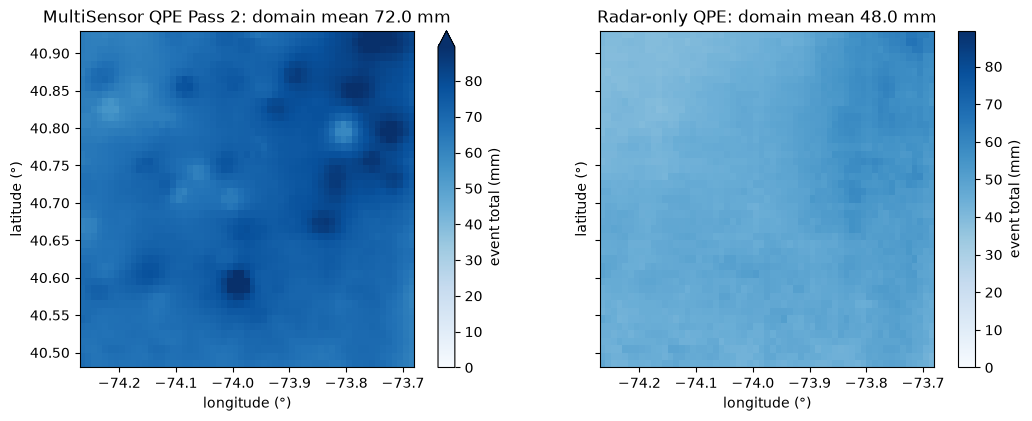

In [4]:
h0, h1 = RU._hour_window(EVENT.start, EVENT.end)
qpe = event_accumulation(h0 - pd.Timedelta('1h'), h1, NYC, client=client)
ro = event_accumulation(h0 - pd.Timedelta('1h'), h1, NYC, product='RadarOnly_QPE_01H', client=client)
print(f"Pass 2: {qpe.attrs['hours_available']}/{qpe.attrs['hours_expected']} hours, "
      f"radar-only: {ro.attrs['hours_available']}/{ro.attrs['hours_expected']} hours")

vmax = float(max(np.nanpercentile(qpe, 99), np.nanpercentile(ro, 99)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, da, title in zip(axes, (qpe, ro), ('MultiSensor QPE Pass 2', 'Radar-only QPE')):
    da.plot(ax=ax, cmap='Blues', vmin=0, vmax=vmax, cbar_kwargs={'label': 'event total (mm)'})
    ax.set(title=f'{title}: domain mean {float(da.mean()):.1f} mm', xlabel='longitude (°)', ylabel='latitude (°)')
    ax.set_aspect(1 / np.cos(np.radians(40.7)))
fig.tight_layout()

Domain-mean hourly QPE (mm per hour) of both products; x = time (UTC, hour-ending).
The hour with the largest Pass-2 domain mean is printed and used below.

peak hour (hour-ending): 2024-03-23 19:00:00


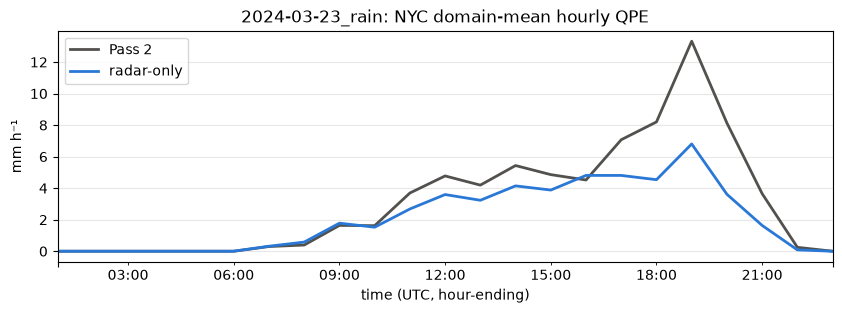

In [5]:
hourly = {name: domain_mean_series(hourly_rainfall(h0 - pd.Timedelta('1h'), h1, NYC, product=prod, client=client))
          for name, prod in (('Pass 2', 'MultiSensor_QPE_01H_Pass2'), ('radar-only', 'RadarOnly_QPE_01H'))}
ax = pd.DataFrame(hourly).plot(figsize=(10, 3), lw=2, color=['#52514e', '#2a78d6'])
ax.set(xlabel='time (UTC, hour-ending)', ylabel='mm h⁻¹', title=f'{EVENT.event}: NYC domain-mean hourly QPE')
ax.grid(alpha=0.3)
PEAK = hourly['Pass 2'].idxmax()
print('peak hour (hour-ending):', PEAK)

`PrecipRate` (mm/h) and `PrecipFlag` (surface precipitation type) every 10 min in the
peak hour (both are 2-min products, subsampled here). Left: rate at the 10-min step with
the highest domain mean; right: type at the same step, one color per code (legend on the
color bar; the code table is printed). x = longitude, y = latitude (°).

{0: 'none', 1: 'warm stratiform rain', 3: 'snow', 6: 'convective rain', 7: 'rain mixed with hail', 10: 'cool stratiform rain', 91: 'tropical/stratiform rain mix', 96: 'tropical/convective rain mix'}


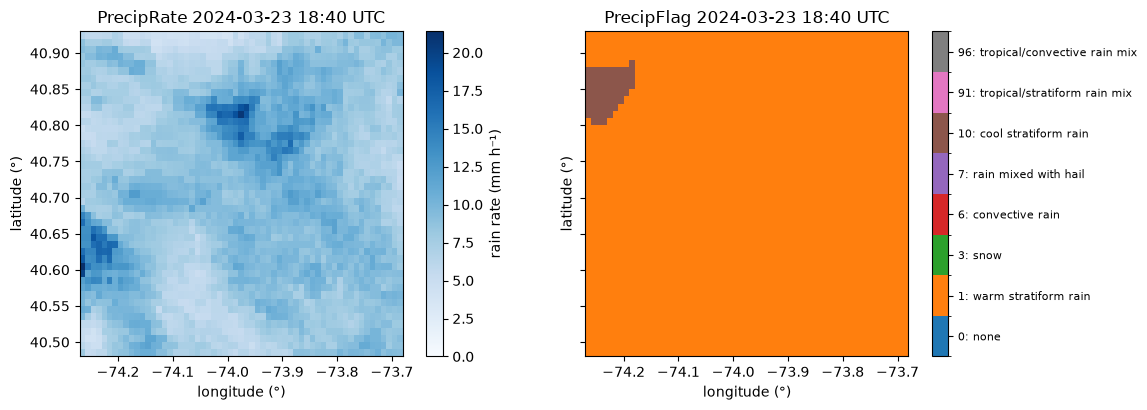

In [6]:
rate = client.load('PrecipRate', PEAK - pd.Timedelta('1h'), PEAK, NYC, freq='10min')
flag = client.load('PrecipFlag', PEAK - pd.Timedelta('1h'), PEAK, NYC, freq='10min')
t_peak = rate.mean(('lat', 'lon')).idxmax().values
print(PRECIP_FLAG)

codes = sorted(PRECIP_FLAG)
f0 = flag.sel(time=t_peak)
pos = f0.copy(data=pd.Series(f0.values.ravel()).map({c: i for i, c in enumerate(codes)})
              .to_numpy(float).reshape(f0.shape))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
rate.sel(time=t_peak).plot(ax=a1, cmap='Blues', vmin=0, cbar_kwargs={'label': 'rain rate (mm h⁻¹)'})
im = pos.plot(ax=a2, cmap=ListedColormap(plt.get_cmap('tab10').colors[:len(codes)]),
              norm=BoundaryNorm(np.arange(len(codes) + 1) - 0.5, len(codes)), add_colorbar=False)
cb = fig.colorbar(im, ax=a2, ticks=range(len(codes)))
cb.ax.set_yticklabels([f'{c}: {PRECIP_FLAG[c]}' for c in codes], fontsize=8)
for ax, name in ((a1, 'PrecipRate'), (a2, 'PrecipFlag')):
    ax.set(title=f'{name} {pd.Timestamp(t_peak):%Y-%m-%d %H:%M} UTC', xlabel='longitude (°)', ylabel='latitude (°)')
    ax.set_aspect(1 / np.cos(np.radians(40.7)))
fig.tight_layout()

## §3. Sensors next to the radar

`RU.load_sensors()` loads the dataset's ASOS (with the `gauge_melt` QC), WU PWS, NY
Mesonet and the 10-min CML attenuation file; a network the dataset lacks is empty.
`RU.merge_event()` brings each sensor to hourly mm and puts the MRMS value next to it:

| network | to hourly mm | MRMS value |
|---|---|---|
| ASOS, WU PWS, Mesonet | sum of the samples in the hour; NaN when < 80 % of samples | QPE in the gauge's grid cell |
| CML (sublinks ≥ 20 GHz) | attenuation (`att_drymed` baseline, dB), outage samples dropped → ITU-R P.838-3 power law → hourly mean rate; NaN with < 5 of 6 samples | QPE averaged along the path |

The table: sensors per network, share of sensor-hours with a value, and the number of
sensor-hours where both the sensor and MRMS Pass 2 have a value.

In [7]:
networks, cml, ghcn = RU.load_sensors()
merged = RU.merge_event(EVENT, networks, cml, client=client)
merged.groupby('network').agg(sensors=('sensor_id', 'nunique'),
                              valid_share=('sensor_mm', lambda x: round(x.notna().mean(), 2)),
                              joint_hours=('sensor_mm', lambda x: int((x.notna() & merged.loc[x.index, 'radar_mm'].notna()).sum())))

  ASOS         5 stations
  WU PWS      37 stations
  Mesonet      0 stations
  CML         63 sublinks (29 ≥ 20 GHz)
  GHCN         0 stations (daily)


,sensors,valid_share,joint_hours
network,,,
ASOS,5,0.85,98
CML,29,0.93,618
WU PWS,37,0.96,816


Map: MRMS Pass-2 event total (mm, blue shading) with each sensor's event total on the
same color scale (large circle = ASOS, square = Mesonet, small dot = WU PWS, small square
= CML path midpoint); sensors with a missing hour are not drawn. x = longitude,
y = latitude (°).

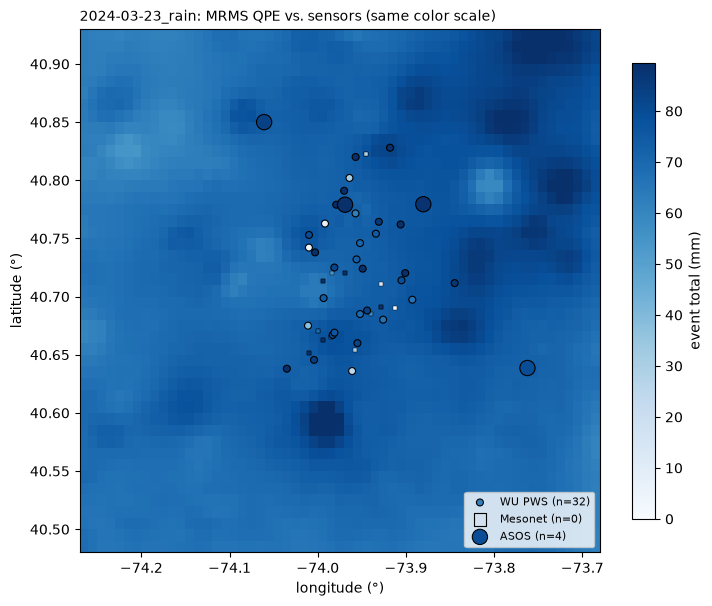

In [8]:
RU.plot_event_map(EVENT, merged, client=client);

Hourly network mean (mm h⁻¹) of each network and of MRMS Pass 2 at the same sensors,
over hours where both have a value; one panel per network, x = time (UTC, hour-ending).

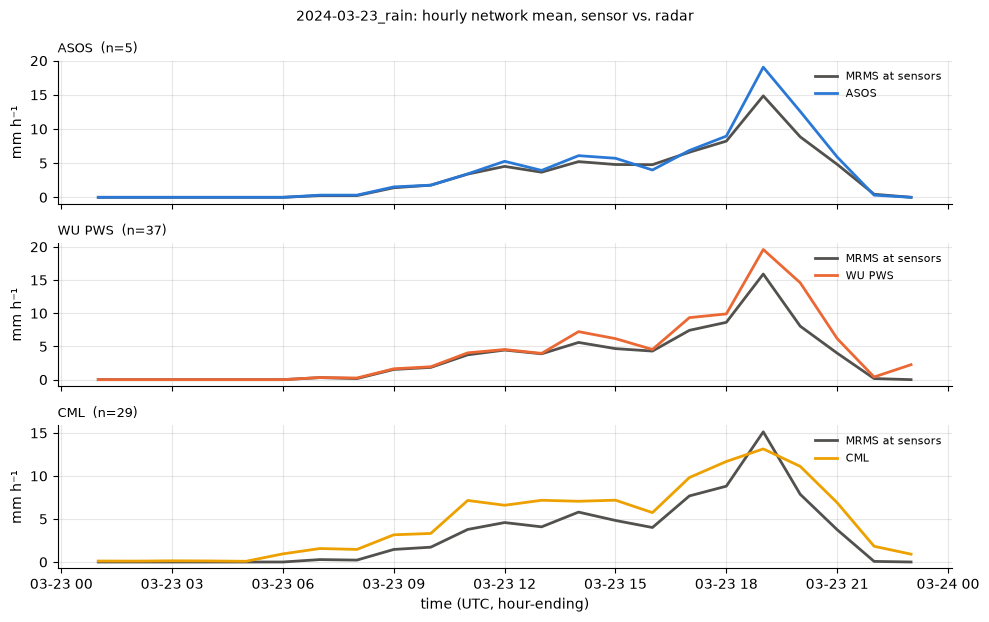

In [9]:
RU.plot_event_timeseries(merged, EVENT.event);

Every sensor-hour: MRMS Pass 2 (x, mm h⁻¹) vs. the sensor (y, mm h⁻¹), one panel per
network, with the 1:1 line and the scores of that panel.

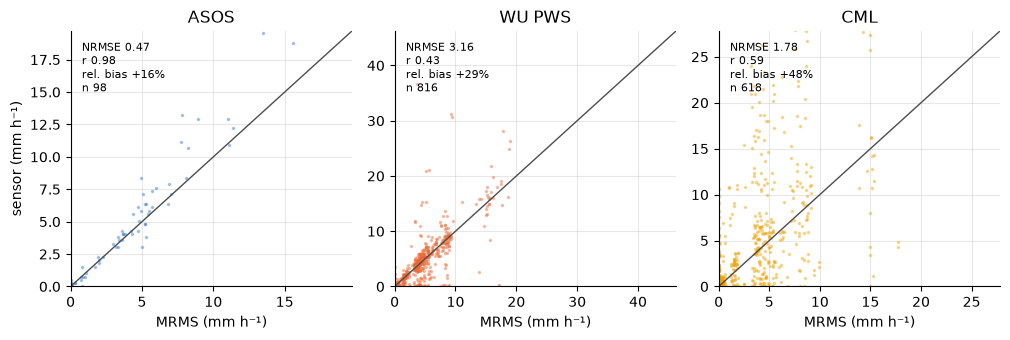

In [10]:
RU.plot_sensor_vs_radar(merged);

**Scores** of the hourly sensor values against MRMS, per network, for both radar
products. `n` = sensor-hours with both values; `n_sensors` = sensors in the group.
bias / mae / rmse in mm h⁻¹; `nrmse` = rmse / mean_ref; `rel_bias` = Σsensor / Σradar − 1;
`corr` = Pearson r; pod / far / csi for "wet" = ≥ 0.1 mm. Groups with fewer than 30
sensor-hours get no metrics.

In [11]:
cols = ['n_sensors', 'n', 'mean_ref', 'mean_est', 'rel_bias', 'rmse', 'nrmse', 'corr', 'pod', 'far', 'csi']
pd.concat({'Pass 2': RU.compare_sensors(merged, reference='radar_mm'),
           'radar-only': RU.compare_sensors(merged, reference='radar_only_mm')},
          names=['reference']).reindex(columns=cols).round(2)

n_sensors    n  mean_ref  mean_est  rel_bias   rmse  nrmse  corr   pod   far   csi
reference  network                                                                                    
Pass 2     ASOS             5   98      3.02      3.51      0.16   1.43   0.47  0.98  0.98  0.07  0.92
           CML             29  618      3.02      4.47      0.48   5.37   1.78  0.59  0.95  0.22  0.75
           WU PWS          37  816      3.18      4.11      0.29  10.05   3.16  0.43  0.94  0.07  0.89
radar-only ASOS             5   98      1.98      3.51      0.77   3.46   1.74  0.87  0.97  0.02  0.95
           CML             29  618      1.94      4.47      1.31   6.03   3.12  0.57  0.95  0.20  0.77
           WU PWS          37  816      2.05      4.11      1.01  10.59   5.17  0.39  0.93  0.05  0.89

## §4. IDW rainfall maps vs. radar

`RM.build_event_maps()` interpolates the hourly sensor values onto the MRMS 0.01° grid
over the OpenMesh link area (IDW, weight 1/d², sensors within 10 km; a CML counts at its
path midpoint) and takes MRMS Pass 2 on the same cells. Maps: **CML**, **PWS** (WU) and
**Gauges** (ASOS + Mesonet + WU PWS); a map is skipped when its network is empty.
`dist_<map>` = km from each cell to the nearest sensor (nearest path for CML).

In [12]:
maps = RM.build_event_maps(merged, EVENT, cml=cml, client=client)
print({v: dict(maps[v].sizes) for v in maps.data_vars if not v.startswith('dist_')})

{'MRMS': {'time': 23, 'lat': 29, 'lon': 16}, 'CML': {'time': 23, 'lat': 29, 'lon': 16}, 'PWS': {'time': 23, 'lat': 29, 'lon': 16}, 'Gauges': {'time': 23, 'lat': 29, 'lon': 16}}


Scores of each map against MRMS, pooled over (hour, cell) pairs within 2 km of that
map's sensors. `n` = (hour, cell) pairs; mean_ref / mean_est / rmse in mm h⁻¹;
`total_nrmse` and `total_rel_bias` compare per-cell event totals.

In [13]:
map_sc = RM.map_scores(maps, near_km=2.0)
map_sc[['n', 'hours', 'mean_ref', 'mean_est', 'rel_bias', 'rmse', 'nrmse', 'corr', 'csi',
        'total_nrmse', 'total_rel_bias']].round(2)

,n,hours,mean_ref,mean_est,rel_bias,rmse,nrmse,corr,csi,total_nrmse,total_rel_bias
map,,,,,,,,,,,
CML,3381,23,3.21,4.55,0.42,3.03,0.95,0.80,0.73,0.66,0.42
PWS,5635,23,3.22,4.16,0.29,6.95,2.16,0.58,0.89,1.18,0.29
Gauges,5727,23,3.22,4.16,0.29,6.88,2.14,0.59,0.89,1.17,0.29


Event totals (mm) of MRMS and each map on one color scale; cells farther than 2 km from
the map's sensors are blank; CML paths drawn as lines, gauges as markers. The bar chart
shows each map's hourly NRMSE from the table above.

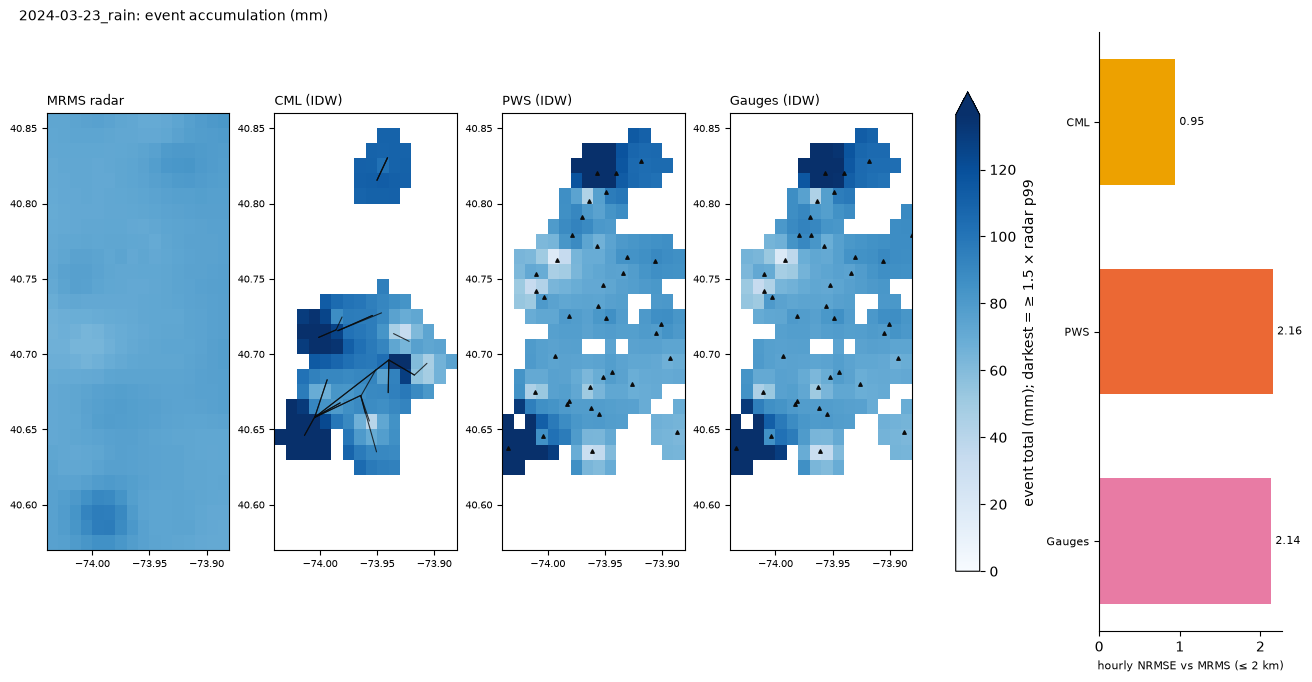

In [14]:
RM.plot_event_totals(maps, merged, cml=cml, near_km=2.0, scores=map_sc);

Hourly maps for the 6 hours around the hour of highest domain-mean MRMS: one row per map
(cells farther than 2 km from its sensors blank), one column per hour (UTC, hour-ending;
mm, shared color scale). The last row is CML minus MRMS (mm; red = CML > MRMS,
blue = CML < MRMS).

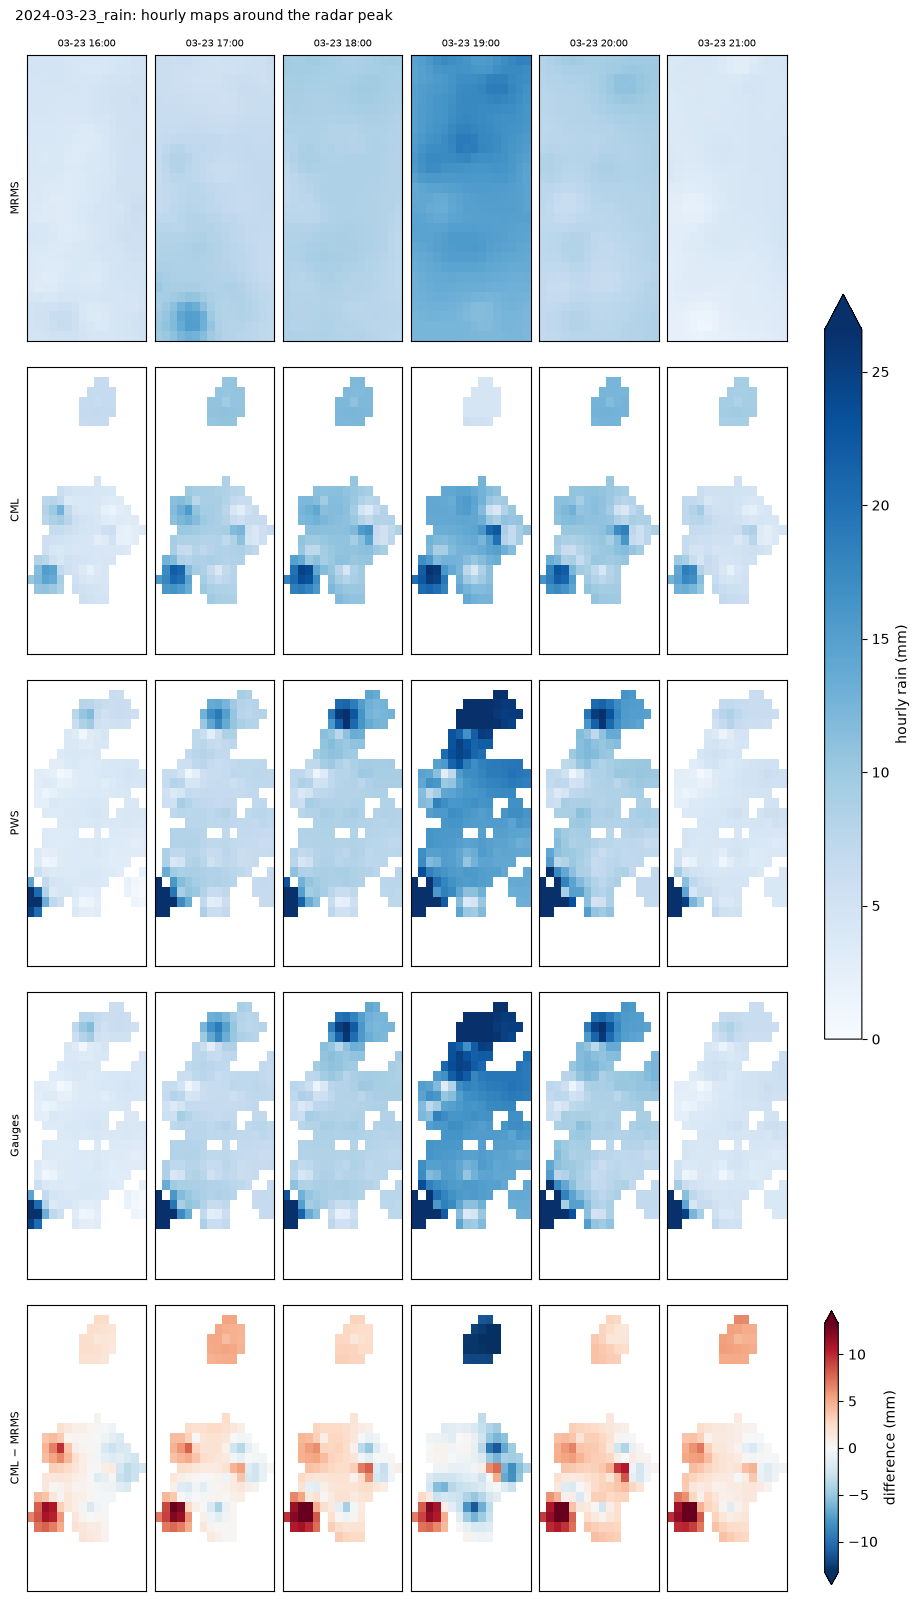

In [15]:
RM.plot_hourly_snapshots(maps, near_km=2.0);

**Other events:** change `EVENT_NAME` in the setup cell (with `'v1'`, an event inside
2023-10-29 → 2024-07-01). `RM.cml_retrieval_qc(merged, EVENT.event)` flags CML links whose
event total departs from their neighbours; pass the flagged ids as `exclude=` to
`RM.build_event_maps`.